## Instalacion de librerias necesarias

In [5]:
pip install psycopg2

   ---------------------------------------- 0.0/2.8 MB ? eta -:--:--
   ---------------------------------------- 2.8/2.8 MB 53.3 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## Importacion de libretias

In [6]:
import pandas as pd
from sqlalchemy import create_engine
from sqlalchemy.types import Boolean
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import joblib

## Configuración a la base de datos PostgreSQL

> **Nota de configuración**: Antes de ejecutar la siguiente celda, sustituye los siguientes parámetros por los de tu entorno:
> - `<USERNAME>`: Nombre de usuario de PostgreSQL asociado a la base de datos a utilizar (ej. `postgres`).
> - `<PASSWORD>`: Contraseña para acceder a la base de datos PostgreSQL.
> - `<DATABASENAME>`: Nombre de la base de datos creada en PostgreSQL (ej. `Sistema_Predictivo_de_Respuesta_Metabolica_y_Nutricion_Clinica`).

In [17]:
# NOTA DE CONFIGURACIÓN - Sustituye <USERNAME>, <PASSWORD> y <DATABASENAME> con tus datos de PostgreSQL
cadena_conexion = 'postgresql+psycopg2://<USERNAME>:<PASSWORD>@host.docker.internal:5432/<DATABASENAME>?client_encoding=utf8'
engine = create_engine(cadena_conexion)

In [19]:
def ejecutar_etl():
    print("Iniciando proceso ETL...")
    
    # 1. Cargar el CSV recuperando el encoding para evitar el UnicodeDecodeError
    df_csv = pd.read_csv('gastrointestinal_disease_dataset.csv', encoding='latin1')
 
    # 2. Renombrar las columnas
    df_csv = df_csv.rename(columns={
        'Diet_Type': 'tipo_dieta',
        'Disease_Class': 'clase_enfermedad',
        'Age': 'edad',
        'Gender': 'genero',
        'BMI': 'imc',
        'Microbiome_Index': 'indice_microbioma',
        'CRP_ESR': 'proteina_c_reactiva',       
        'Fecal_Calprotectin': 'calprotectina_fecal',
        'Antibiotic_Use': 'uso_antibioticos'    
    })

    # 3. Forzar la conversión a booleano SIEMPRE (sin el if) para transformar los 0 y 1
    df_csv['uso_antibioticos'] = df_csv['uso_antibioticos'].astype(bool)

    # 4. Procesar e insertar Catálogo de Dietas
    print("Procesando Catálogo de Dietas...")
    df_dietas = pd.DataFrame(df_csv['tipo_dieta'].dropna().unique(), columns=['tipo_dieta'])
    df_dietas.to_sql('cat_dietas', engine, if_exists='append', index=False)
    
    # 5. Procesar e insertar Catálogo de Enfermedades
    print("Procesando Catálogo de Enfermedades...")
    df_enfermedades = pd.DataFrame(df_csv['clase_enfermedad'].dropna().unique(), columns=['clase_enfermedad'])
    df_enfermedades.to_sql('cat_enfermedades', engine, if_exists='append', index=False)
    
    # 6. Recuperar los IDs generados por PostgreSQL
    db_dietas = pd.read_sql("SELECT id_dieta, tipo_dieta FROM cat_dietas", engine)
    db_enfermedades = pd.read_sql("SELECT id_enfermedad, clase_enfermedad FROM cat_enfermedades", engine)
    
    df_csv = df_csv.merge(db_dietas, on='tipo_dieta', how='left')
    df_csv = df_csv.merge(db_enfermedades, on='clase_enfermedad', how='left')

    # 7. Procesar e insertar Tabla de Pacientes
    print("Procesando Tabla de Pacientes...")
    df_pacientes = df_csv[['edad', 'genero', 'imc']].copy()
    df_pacientes.to_sql('pacientes', engine, if_exists='append', index=False)
    
    db_pacientes = pd.read_sql("SELECT id_paciente FROM pacientes ORDER BY id_paciente ASC", engine)
    df_csv['id_paciente'] = db_pacientes['id_paciente']

    # 8. Procesar e insertar Tabla Central (Registros Clínicos)
    print("Procesando Tabla de Registros Clínicos...")
    df_registros = df_csv[[
        'id_paciente', 
        'id_dieta', 
        'id_enfermedad', 
        'indice_microbioma', 
        'proteina_c_reactiva', 
        'calprotectina_fecal', 
        'uso_antibioticos'
    ]].copy()
    
    # Insertar forzando la traducción exacta a Boolean de SQL
    df_registros.to_sql('registros_clinicos', engine, if_exists='append', index=False, dtype={'uso_antibioticos': Boolean})
    
    print("¡ETL completado exitosamente! Los datos están normalizados en SQL.")

if __name__ == "__main__":
    ejecutar_etl()

Iniciando proceso ETL...
Procesando Catálogo de Dietas...


UnicodeDecodeError: 'utf-8' codec can't decode byte 0xed in position 103: invalid continuation byte

In [30]:
# La consulta SQL compleja
# Unimos la tabla de hechos con sus catálogos y dimensiones para reconstruir el historial clínico
consulta_sql = """
    SELECT 
        p.edad, 
        p.genero, 
        p.imc, 
        d.tipo_dieta, 
        r.indice_microbioma, 
        r.proteina_c_reactiva, 
        r.calprotectina_fecal,
        r.uso_antibioticos,
        e.clase_enfermedad AS target_enfermedad
    FROM registros_clinicos r
    INNER JOIN pacientes p ON r.id_paciente = p.id_paciente
    INNER JOIN cat_dietas d ON r.id_dieta = d.id_dieta
    INNER JOIN cat_enfermedades e ON r.id_enfermedad = e.id_enfermedad;
"""

# 3. Cargar los datos en un DataFrame de Pandas
print("Ejecutando JOINs y extrayendo datos de PostgreSQL...")
df_ml = pd.read_sql(consulta_sql, engine)

# 4. Preprocesamiento para Scikit-Learn (Feature Engineering)
print("Aplicando One-Hot Encoding a variables categóricas...")

# Scikit-Learn requiere matrices puramente numéricas. 
# Transformamos el texto (ej. "Dieta Vegana", "Femenino") en columnas binarias (ceros y unos).
columnas_categoricas = ['genero', 'tipo_dieta']
df_ml_procesado = pd.get_dummies(df_ml, columns=columnas_categoricas, drop_first=True)

# Convertimos explícitamente el booleano de SQL (True/False) a entero (1/0) para el modelo
df_ml_procesado['uso_antibioticos'] = df_ml_procesado['uso_antibioticos'].astype(int)

# 5. Separar las Features o características (X) y el Target o predicción (y)
X = df_ml_procesado.drop('target_enfermedad', axis=1)
y = df_ml_procesado['target_enfermedad']

# 6. Dividir en conjunto de Entrenamiento (80%) y Prueba (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("\n¡Datos listos para entrenar!")
print(f"Tamaño del set de entrenamiento: {X_train.shape}")
print(f"Tamaño del set de prueba: {X_test.shape}")

print("\nVista previa de la matriz de características procesada (X_train):")
print(X_train.head())

Ejecutando JOINs y extrayendo datos de PostgreSQL...
Aplicando One-Hot Encoding a variables categóricas...

¡Datos listos para entrenar!
Tamaño del set de entrenamiento: (24448, 10)
Tamaño del set de prueba: (6112, 10)

Vista previa de la matriz de características procesada (X_train):
       edad   imc  indice_microbioma  proteina_c_reactiva  \
6918     75  19.1               0.74                 74.5   
28863    12  34.9               0.40                 99.6   
22815    69  28.3               0.65                 86.4   
10231     6  16.3               0.63                 76.4   
5550     36  34.5               0.76                 73.8   

       calprotectina_fecal  uso_antibioticos  genero_Male  \
6918                 462.0                 1         True   
28863                141.0                 0        False   
22815                 63.0                 1        False   
10231                231.0                 1         True   
5550                 122.0                

Entrenando el modelo Random Forest Classifier...
✅ Reporte de clasificación guardado en: 'reporte_metricas_clinicas.txt'
✅ Tabla de importancia de variables guardada en: 'importancia_biomarcadores.csv'


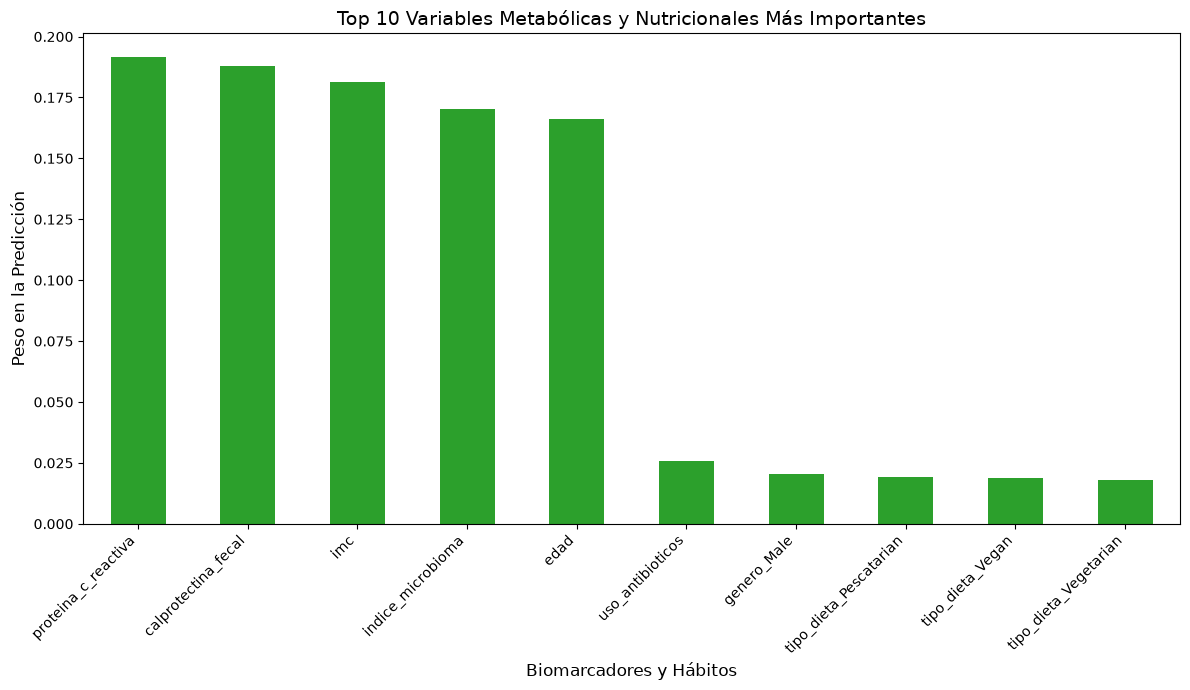

✅ Gráfico de barras guardado en: 'grafico_importancia_variables.png'


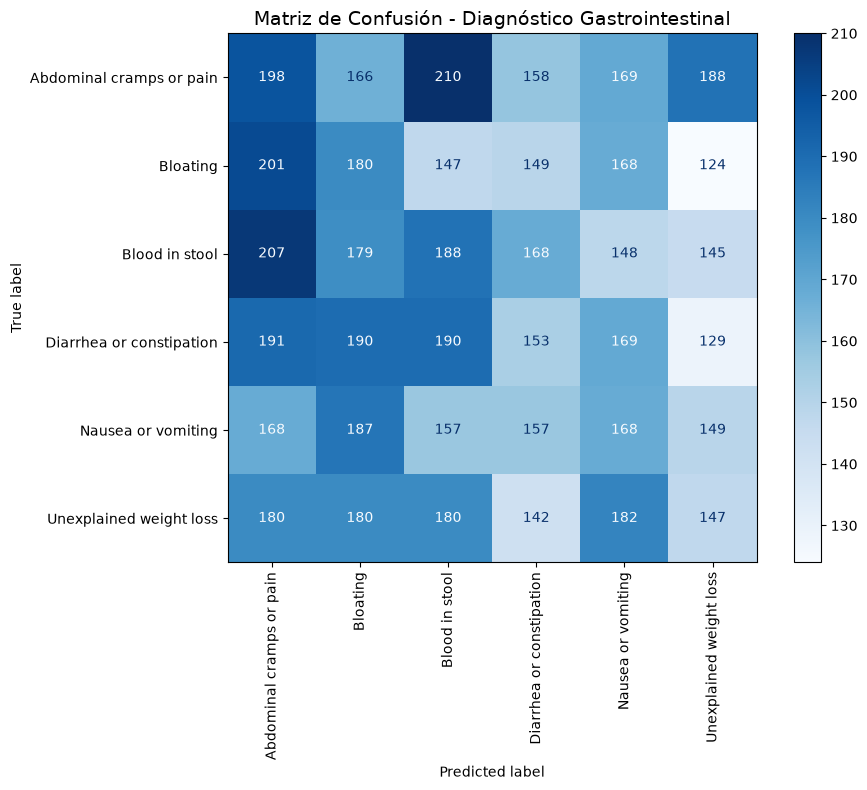

✅ Matriz de confusión guardada en: 'matriz_confusion_alta_calidad.png'


In [41]:
# 1. Instanciar el modelo
# Usamos class_weight='balanced' porque los datasets médicos suelen tener desequilibrio de clases 
# (ej. muchos registros de 'Sano' y pocos de 'Crohn')
modelo_rf = RandomForestClassifier(
    n_estimators=100, 
    random_state=42, 
    class_weight='balanced', 
    n_jobs=-1 # Usa todos los núcleos del procesador para acelerar el entrenamiento
)

# 2. Entrenar el algoritmo
print("Entrenando el modelo Random Forest Classifier...")
modelo_rf.fit(X_train, y_train)

# 3. Realizar predicciones con el conjunto de prueba (20% de datos no vistos)
y_pred = modelo_rf.predict(X_test)

reporte = classification_report(y_test, y_pred)

with open("reporte_metricas_clinicas.txt", "w", encoding="utf-8") as archivo_texto:
    archivo_texto.write("REPORTE DE CLASIFICACIÓN DEL MODELO PREDICTIVO\n")
    archivo_texto.write("="*60 + "\n")
    archivo_texto.write(reporte)

print("✅ Reporte de clasificación guardado en: 'reporte_metricas_clinicas.txt'")

# ---------------------------------------------------------
# 2. Exportar la Importancia de las Características (CSV y PNG)
# ---------------------------------------------------------
importancias = pd.Series(modelo_rf.feature_importances_, index=X_train.columns)
importancias = importancias.sort_values(ascending=False)

# Guardar la tabla completa en un archivo CSV para inspección detallada
importancias.to_csv("importancia_biomarcadores.csv", header=["Nivel_Importancia"])
print("✅ Tabla de importancia de variables guardada en: 'importancia_biomarcadores.csv'")

# Generar un gráfico de barras con el top 10 y guardarlo como imagen
fig_feat, ax_feat = plt.subplots(figsize=(12, 7))
importancias.head(10).plot(kind='bar', color='#2ca02c', ax=ax_feat)

plt.title('Top 10 Variables Metabólicas y Nutricionales Más Importantes', fontsize=14)
plt.ylabel('Peso en la Predicción', fontsize=12)
plt.xlabel('Biomarcadores y Hábitos', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

# Exportar en alta resolución (300 DPI)
plt.savefig('grafico_importancia_variables.png', dpi=300)
plt.show()
plt.close(fig_feat)
print("✅ Gráfico de barras guardado en: 'grafico_importancia_variables.png'")


# ---------------------------------------------------------
# 3. Exportar la Matriz de Confusión a PNG
# ---------------------------------------------------------
fig_conf, ax_conf = plt.subplots(figsize=(10, 8))

disp = ConfusionMatrixDisplay.from_estimator(
    modelo_rf, 
    X_test, 
    y_test, 
    cmap=plt.cm.Blues, 
    xticks_rotation='vertical',
    ax=ax_conf
)

plt.title('Matriz de Confusión - Diagnóstico Gastrointestinal', fontsize=14)
plt.tight_layout()

# bbox_inches='tight' evita que los bordes o etiquetas largas queden fuera de la imagen
plt.savefig('matriz_confusion_alta_calidad.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close(fig_conf)
print("✅ Matriz de confusión guardada en: 'matriz_confusion_alta_calidad.png'")


In [35]:
# Guardar el modelo entrenado
joblib.dump(modelo_rf, 'modelo_metabolico.pkl')

# Guardar la lista exacta de características (Features)
joblib.dump(X_train.columns.tolist(), 'columnas_entrenamiento.pkl')

print("Modelo y columnas exportados correctamente.")

Modelo y columnas exportados correctamente.
